In [1]:
!pip install deepxde

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 184.4/184.4 kB 4.3 MB/s eta 0:00:00


In [2]:
import deepxde as dde

No backend selected.
Finding available backend...


Using backend: tensorflow.compat.v1
Other supported backends: tensorflow, pytorch, jax, paddle.
paddle supports more examples now and is recommended.


Found tensorflow.compat.v1
Setting the default backend to "tensorflow.compat.v1". You can change it in the ~/.deepxde/config.json file or export the DDE_BACKEND environment variable. Valid options are: tensorflow.compat.v1, tensorflow, pytorch, jax, paddle (all lowercase)


Enable just-in-time compilation with XLA.



In [3]:
from deepxde.backend import tf

In [4]:
import matplotlib.pyplot as plt
import numpy as np

Defining derivative

In [5]:
def pde(x,y):
    dy_xx = dde.grad.hessian(y,x)
    return dy_xx + np.pi**2*tf.sin(np.pi*x)

Defining Geometry

In [6]:
geom = dde.geometry.Interval(-1,1)

Defining Boundary

In [7]:
def boundary(x, on_boundary):
    return on_boundary
def boundary_func(x):
    return 0

In [8]:
def exact_sol(x):    # to evaluate error
    return np.sin(np.pi*x)

Dirichlet Boundary Condition

In [9]:
bc = dde.icbc.DirichletBC(geom, boundary_func, boundary)
data = dde.data.PDE(geom, pde, bc, 16, 2, solution=exact_sol, num_test=100)

In [10]:
layer_size = [1] + [50]*3 + [1]
activation = "tanh"
initializer = "Glorot uniform"
net = dde.nn.FNN(layer_size, activation, initializer)

Model

In [11]:
model = dde.Model(data, net)
model.compile("adam", lr=0.001, metrics=["l2 relative error"])
losshistory, train_state = model.train(iterations=1000)

Compiling model...
Building feed-forward neural network...
'build' took 0.079665 s

'compile' took 1.001073 s



I0000 00:00:1731938126.365722      76 service.cc:145] XLA service 0x7ef3800151a0 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1731938126.365779      76 service.cc:153]   StreamExecutor device (0): Tesla T4, Compute Capability 7.5
I0000 00:00:1731938126.365786      76 service.cc:153]   StreamExecutor device (1): Tesla T4, Compute Capability 7.5
I0000 00:00:1731938127.110671      76 device_compiler.h:188] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


Training model...

Step      Train loss              Test loss               Test metric   
0         [4.29e+01, 4.59e-02]    [4.86e+01, 4.59e-02]    [8.65e-01]    
1000      [2.47e-04, 9.61e-08]    [2.38e-04, 9.61e-08]    [3.31e-04]    

Best model at step 1000:
  train loss: 2.48e-04
  test loss: 2.38e-04
  test metric: [3.31e-04]

'train' took 3.793700 s



Result visualization

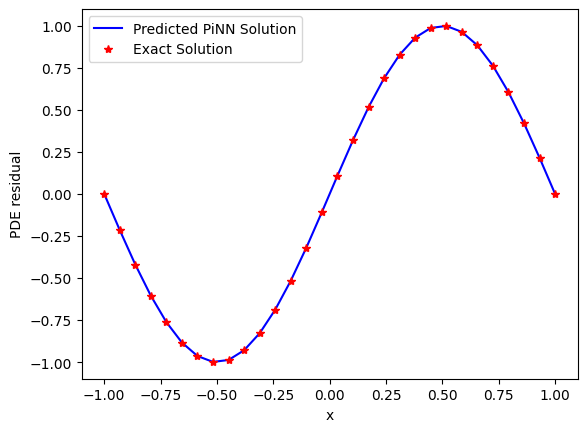

In [12]:
# Plot PDE residual
x = geom.uniform_points(30, True)
y_pred = model.predict(x)
y_exact = exact_sol(x)
plt.figure()
plt.plot(x, y_pred, color='b', label='Predicted PiNN Solution')
plt.plot(x, y_exact, '*', color='r', label='Exact Solution')
plt.xlabel("x")
plt.ylabel("PDE residual")
plt.legend(loc='best')
plt.show()